# Task 4 — Judge honestly: metrics, calibration and risk bands

**Goal:** evaluate the Task 3 logistic-regression baseline with metrics that suit a rare outcome, check whether its scores can be read as probabilities, turn the scores into **High / Medium / Low** risk bands, and write a one-page note a manager can use.

**Everything here uses out-of-fold scores** (every person is scored by a model that never saw them), with the same stratified 5 folds as Task 3. To reproduce the numbers, charts and note, place `02_CortexHR_AI_ML_Dataset.xlsx` in `data/raw/` and run this notebook top to bottom.

> *About the helpers:* the task mentions a provided file `cortexhr_helpers.py` (`binary_report`, `risk_bands`). It was not available, so `src/cortexhr/evaluation.py` contains independent implementations with the same names. Compare signatures if your team's file differs.

| # | Section |
|---|---------|
| 1 | The scores (same as Task 3) |
| 2 | `binary_report`: reading every number |
| 3 | PR-AUC in plain words |
| 4 | Calibration: does 30% really mean 3 in 10? |
| 5 | Risk bands and what share of leavers they catch |
| 6 | Lift chart: top 10% vs picking at random |
| 7 | Are the results stable? (folds, sources, noise) |
| 8 | Metrics table for all baselines |
| 9 | The one-page manager note |

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
candidates = (ROOT, ROOT / "cortexhr-ml", ROOT / "files" / "cortexhr-ml", *ROOT.parents)
ROOT = next((path for path in candidates if (path / "requirements.txt").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Could not locate the CortexHR project; open this notebook from the project folder.")
sys.path.insert(0, str(ROOT / "src"))

from cortexhr.paths import FIGURES, TABLES, REPORTS, DATA_PROCESSED, WORKBOOK
from cortexhr.baselines import load_model_table, make_folds, make_models, model_pipeline, out_of_fold_proba, RANDOM_STATE
from cortexhr.evaluation import (binary_report, risk_bands, band_summary, calibration_table, expected_calibration_error, calibrated_logreg,
                                 lift_table, gains_curve, bootstrap_ci, top_k_mask, BAND_LABELS)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_colwidth", 90)
if not WORKBOOK.is_file():
    raise FileNotFoundError(f"Required source workbook not found: {WORKBOOK}. Copy the workbook into data/raw/ and rerun.")
for d in (FIGURES, TABLES, DATA_PROCESSED): d.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, GREY, RED, GREEN = "#2F5D8A", "#E07B39", "#9AA5B1", "#C0392B", "#3B8C5A"
BAND_COLOURS = {"High": RED, "Medium": ORANGE, "Low": BLUE}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 170, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9.5, "axes.titleweight": "bold"})
R = {}

## 1. The scores
Same rows, same stratified folds (`random_state=42`) and same model as Task 3: logistic regression with `class_weight="balanced"`, with the Day 2 feature pipeline inside every fold.

In [2]:
X, y, source = load_model_table()
folds = make_folds(y)
models = make_models()
score = out_of_fold_proba(model_pipeline(models["Logistic Regression (balanced)"]), X, y, folds)     # Task 3 baseline

# the same numbers as Task 3?  (guards against silently evaluating a different model)
task3 = json.loads((TABLES / "day3_findings.json").read_text(encoding="utf-8"))["summary"]["Logistic Regression (balanced)"]["roc_auc_pooled"]
rep = binary_report(y, score)
assert abs(rep["roc_auc"] - task3) < 1e-9, "scores differ from the Task 3 baseline"
R["rows"], R["leavers"], R["prevalence"] = len(y), int(y.sum()), float(y.mean())
print(f"{len(y):,} people, {int(y.sum())} leavers ({100*y.mean():.1f}%). ROC-AUC {rep['roc_auc']:.4f} = Task 3 pooled value {task3:.4f}")
print(f"scores range from {score.min():.3f} to {score.max():.3f}; average score {score.mean():.3f}")

2,379 people, 349 leavers (14.7%). ROC-AUC 0.7103 = Task 3 pooled value 0.7103
scores range from 0.004 to 0.977; average score 0.405


## 2. `binary_report`: reading every number
Pass the out-of-fold scores in; the report covers ranking quality, the top-10% list HR would actually review, yes/no behaviour at a 0.5 cut-off, and probability quality.

In [3]:
rep = binary_report(y, score, top_frac=0.10, threshold=0.5)
R["report_as_trained"] = rep
meaning = [
 ("roc_auc",          f"{rep['roc_auc']:.3f}", "Pick one leaver and one stayer at random: this is the chance the leaver gets the higher score. 0.5 = coin flip, 1.0 = perfect."),
 ("pr_auc",           f"{rep['pr_auc']:.3f}", f"How well leavers are concentrated at the TOP of the list (see section 3). A useless list scores the share of leavers, {rep['pr_auc_baseline']:.3f}."),
 ("top_k_people",     f"{rep['top_k_people']}", "Size of the top-10% list."),
 ("precision_at_top", f"{rep['precision_at_top']:.3f}", "Of the people in the top 10%, the share who really left."),
 ("recall_at_top",    f"{rep['recall_at_top']:.3f}", "Of everyone who left, the share that sits in the top 10%."),
 ("lift_at_top",      f"{rep['lift_at_top']:.2f}", "Top-10% precision divided by the overall leaver rate: how many times better than a random list of the same size."),
 ("flagged_share",    f"{rep['flagged_share']:.3f}", "Share of people with score >= 0.5 (the 'yes' answers)."),
 ("precision @0.5",   f"{rep['precision']:.3f}", "Of those flagged 'yes' at 0.5, the share who really left."),
 ("recall @0.5",      f"{rep['recall']:.3f}", "Of everyone who left, the share flagged 'yes' at 0.5."),
 ("accuracy @0.5",    f"{rep['accuracy']:.3f}", f"Share of right yes/no answers. Misleading here: always saying 'stays' would score {1 - rep['prevalence']:.3f}."),
 ("brier",            f"{rep['brier']:.3f}", f"Average squared error of the scores read as probabilities (lower is better). Giving everyone the average rate scores {rep['brier_baseline']:.3f}."),
]
display(pd.DataFrame(meaning, columns=["number", "value", "what it means"]))

,number,value,what it means
0,roc_auc,0.710,Pick one leaver and one stayer at random: this is the chance the leaver gets the highe...
1,pr_auc,0.298,How well leavers are concentrated at the TOP of the list (see section 3). A useless li...
2,top_k_people,238,Size of the top-10% list.
3,precision_at_top,0.332,"Of the people in the top 10%, the share who really left."
4,recall_at_top,0.226,"Of everyone who left, the share that sits in the top 10%."
5,lift_at_top,2.26,Top-10% precision divided by the overall leaver rate: how many times better than a ran...
6,flagged_share,0.353,Share of people with score >= 0.5 (the 'yes' answers).
7,precision @0.5,0.263,"Of those flagged 'yes' at 0.5, the share who really left."
8,recall @0.5,0.633,"Of everyone who left, the share flagged 'yes' at 0.5."
9,accuracy @0.5,0.686,Share of right yes/no answers. Misleading here: always saying 'stays' would score 0.853.


**Reading them together.** The *ranking* is genuinely informative (ROC-AUC 0.71, top-10% lift above 2). But two numbers warn us: accuracy at 0.5 looks fine only by accident, and the **Brier score is worse than the do-nothing baseline** — a first hint that the scores are not trustworthy as probabilities (section 4).

## 3. PR-AUC in plain words
*Imagine the whole company ranked from most to least at risk. You walk down the list.* At each step two questions matter:

* **Precision** — of the people I have picked so far, how many really leave?
* **Recall** — of everyone who leaves, how many have I picked so far?

PR-AUC is the average precision as you walk down the list. If leavers are packed near the top, precision stays high for a long time and PR-AUC is high. If leavers are spread randomly, precision stays at the company-wide leaver rate. That is why a useless model scores about 0.147 here (the share of leavers), not 0.5 like ROC-AUC.

In [4]:
# a tiny worked example: 10 people, 3 leavers, ranked by score (1 = leaves)
toy = pd.DataFrame({"rank": range(1, 11), "left": [1, 0, 1, 0, 0, 1, 0, 0, 0, 0]})
toy["leavers found so far"] = toy.left.cumsum()
toy["precision so far"] = (toy["leavers found so far"] / toy["rank"]).round(2)
toy["recall so far"] = (toy["leavers found so far"] / toy.left.sum()).round(2)
display(toy)
from sklearn.metrics import average_precision_score
print("PR-AUC of this toy list:", round(average_precision_score(toy.left, -toy["rank"]), 3), "| a random order would give about", toy.left.mean())
print(f"\nOur model: PR-AUC {rep['pr_auc']:.3f} vs {rep['pr_auc_baseline']:.3f} for a useless list -> about {rep['pr_auc'] / rep['pr_auc_baseline']:.1f}x better at keeping leavers near the top.")

,rank,left,leavers found so far,precision so far,recall so far
0,1,1,1,1.00,0.33
1,2,0,1,0.50,0.33
2,3,1,2,0.67,0.67
3,4,0,2,0.50,0.67
4,5,0,2,0.40,0.67
5,6,1,3,0.50,1.00
6,7,0,3,0.43,1.00
7,8,0,3,0.38,1.00
8,9,0,3,0.33,1.00
9,10,0,3,0.30,1.00


PR-AUC of this toy list: 0.722 | a random order would give about 0.3

Our model: PR-AUC 0.298 vs 0.147 for a useless list -> about 2.0x better at keeping leavers near the top.


## 4. Calibration: does 30% really mean 3 in 10?
Group people by predicted score (10 equal-size groups). In each group compare the **average predicted score** with the **share who really left**. On the diagonal, a score of 30% means 3 in 10.

In [5]:
cal = calibration_table(y, score, n_bins=10, strategy="quantile")
ece = expected_calibration_error(cal)
display(cal.round(3))
print(f"average predicted {score.mean():.3f} vs actual leaver rate {y.mean():.3f} | ECE (average gap) {ece:.3f} | Brier {rep['brier']:.3f} vs do-nothing {rep['brier_baseline']:.3f}")
band_27 = cal.iloc[(cal.mean_predicted - 0.27).abs().argmin()]
print(f"e.g. the group whose average score is {band_27.mean_predicted:.0%}: only {band_27.observed_rate:.0%} actually left")
R["calibration_as_trained"] = {"ece": ece, "mean_predicted": float(score.mean()), "table": cal.to_dict("records")}

,bin,people,mean_predicted,observed_rate,leavers
0,1,238,0.051,0.034,8
1,2,238,0.130,0.046,11
2,3,238,0.203,0.097,23
3,4,238,0.269,0.080,19
4,5,237,0.341,0.089,21
5,6,238,0.418,0.113,27
6,7,238,0.501,0.202,48
7,8,238,0.595,0.210,50
8,9,238,0.701,0.265,63
9,10,238,0.846,0.332,79


average predicted 0.405 vs actual leaver rate 0.147 | ECE (average gap) 0.259 | Brier 0.206 vs do-nothing 0.125
e.g. the group whose average score is 27%: only 8% actually left


**What the curve shows.** The points sit far **below** the diagonal: the model *over-states* risk for almost everyone (average score ~40% against a real rate of ~15%). The reason is `class_weight="balanced"`: it deliberately makes leavers count about six times more during training, which pushes every score up. That is fine for *ranking* people, but the numbers are **not probabilities**. A score of 27% in this model corresponds to roughly 8% who actually leave.

**The fix** is to map the scores onto real leaver rates (Platt scaling, learned only on each fold's training data, so the result stays honest). It keeps the ranking almost unchanged and makes the numbers readable as probabilities.

In [6]:
score_cal = out_of_fold_proba(model_pipeline(calibrated_logreg()), X, y, folds)
rep_cal = binary_report(y, score_cal)
cal_c = calibration_table(y, score_cal, n_bins=10, strategy="quantile")
ece_c = expected_calibration_error(cal_c)
R["report_calibrated"] = rep_cal
R["calibration_calibrated"] = {"ece": ece_c, "mean_predicted": float(score_cal.mean()), "table": cal_c.to_dict("records")}
cmp = pd.DataFrame({"": ["ROC-AUC", "PR-AUC", "average score (actual rate = %.3f)" % y.mean(), "ECE (average gap, lower is better)", "Brier (lower is better; do-nothing = %.3f)" % rep["brier_baseline"], "top-10% precision", "top-10% recall"],
                    "as trained (balanced)": [rep["roc_auc"], rep["pr_auc"], score.mean(), ece, rep["brier"], rep["precision_at_top"], rep["recall_at_top"]],
                    "after calibration": [rep_cal["roc_auc"], rep_cal["pr_auc"], score_cal.mean(), ece_c, rep_cal["brier"], rep_cal["precision_at_top"], rep_cal["recall_at_top"]]}).set_index("")
display(cmp.round(3))
print("ranking agreement between the two scores (Spearman):", round(pd.Series(score).corr(pd.Series(score_cal), method="spearman"), 4))

,as trained (balanced),after calibration
,,
ROC-AUC,0.710,0.711
PR-AUC,0.298,0.296
average score (actual rate = 0.147),0.405,0.151
"ECE (average gap, lower is better)",0.259,0.019
Brier (lower is better; do-nothing = 0.125),0.206,0.116
top-10% precision,0.332,0.332
top-10% recall,0.226,0.226


ranking agreement between the two scores (Spearman): 0.9972


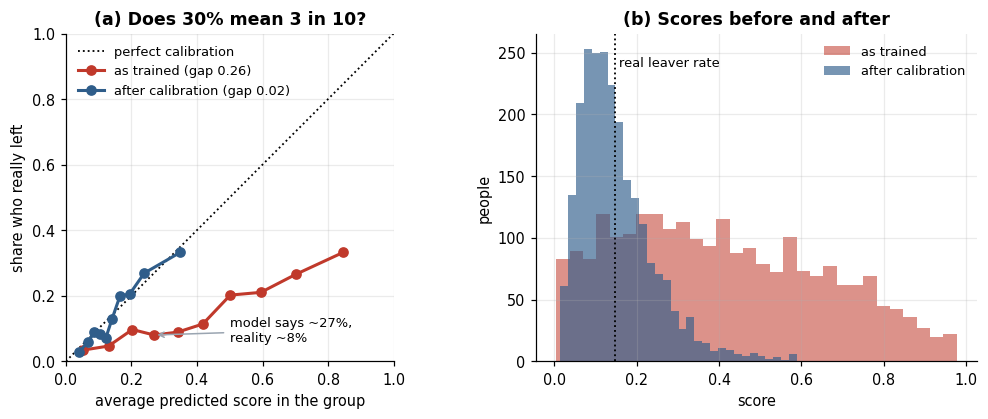

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 3.9), gridspec_kw={"width_ratios": [1.15, 1]})
a1.plot([0, 1], [0, 1], ":", color="k", lw=1.2, label="perfect calibration")
a1.plot(cal.mean_predicted, cal.observed_rate, "o-", color=RED, lw=2, label=f"as trained (gap {ece:.2f})")
a1.plot(cal_c.mean_predicted, cal_c.observed_rate, "o-", color=BLUE, lw=2, label=f"after calibration (gap {ece_c:.2f})")
a1.set_xlim(0, 1); a1.set_ylim(0, 1); a1.set_xlabel("average predicted score in the group"); a1.set_ylabel("share who really left")
a1.set_title("(a) Does 30% mean 3 in 10?"); a1.legend(frameon=False, fontsize=8.5, loc="upper left"); a1.set_aspect("equal")
a1.annotate("model says ~27%,\nreality ~8%", xy=(cal.mean_predicted.iloc[3], cal.observed_rate.iloc[3]), xytext=(0.5, 0.06), fontsize=8.5, arrowprops=dict(arrowstyle="->", color=GREY))
a2.hist(score, bins=30, color=RED, alpha=.55, label="as trained"); a2.hist(score_cal, bins=30, color=BLUE, alpha=.65, label="after calibration")
a2.axvline(y.mean(), color="k", ls=":", lw=1.2); a2.text(y.mean() + .01, a2.get_ylim()[1] * .9, "real leaver rate", fontsize=8.5)
a2.set_xlabel("score"); a2.set_ylabel("people"); a2.set_title("(b) Scores before and after"); a2.legend(frameon=False, fontsize=8.5)
plt.tight_layout(); plt.savefig(FIGURES / "fig7_calibration.png"); plt.show()

**Decision.** From here on the **risk score is the calibrated one** (it can honestly be shown as a percentage). Bands depend only on the *ranking*, so they are almost the same either way (section 5 shows how few people change band). The as-trained score stays in the metrics table for comparison.

## 5. Risk bands
`risk_bands(score)`: **High** = the top 10% of scores, **Medium** = the next 20%, **Low** = the remaining 70%. Group sizes are exact and depend only on rank.

In [8]:
bands = risk_bands(score_cal, high=0.10, medium=0.20, index=y.index)
bs = band_summary(y, bands)
R["bands"] = bs.to_dict("records")
display(bs.assign(share_of_people=lambda d: d.share_of_people.round(3), leaver_rate=lambda d: d.leaver_rate.round(3),
                  lift=lambda d: d.lift.round(2), share_of_all_leavers=lambda d: d.share_of_all_leavers.round(3)))
high, med, low = (bs.set_index("band").loc[b] for b in ("High", "Medium", "Low"))
print(f"People per band: High {int(high.people)}, Medium {int(med.people)}, Low {int(low.people)} (total {int(bs.people.sum())})")
print(f"Share of REAL leavers in the High band: {int(high.leavers)} of {R['leavers']} = {high.share_of_all_leavers:.1%} (a random 10% would hold 10%)")
print(f"High + Medium together: {(high.leavers + med.leavers) / R['leavers']:.1%} of leavers in {(high.people + med.people) / len(y):.0%} of people")
print(f"But {int(low.leavers)} of {R['leavers']} leavers ({low.share_of_all_leavers:.1%}) are in the LOW band: the list misses many leavers.")

lo_p, hi_p = bootstrap_ci(lambda a, s: binary_report(a, s)["precision_at_top"], y, score_cal)
lo_r, hi_r = bootstrap_ci(lambda a, s: binary_report(a, s)["recall_at_top"], y, score_cal)
R["high_band_ci"] = {"precision": [lo_p, hi_p], "recall": [lo_r, hi_r]}
print(f"95% bootstrap intervals: High-band leaver rate {lo_p:.1%} to {hi_p:.1%}; share of leavers caught {lo_r:.1%} to {hi_r:.1%}")

# what the calibrated score means inside each band
mean_pred = pd.Series(score_cal).groupby(bands.values).mean()
check = pd.DataFrame({"average calibrated score": mean_pred, "actual leaver rate": y.groupby(bands.values).mean()}).loc[["High", "Medium", "Low"]]
display(check.round(3)); R["band_calibration"] = check.round(4).to_dict()

# how different would the bands be with the as-trained score?
bands_old = risk_bands(score, index=y.index)
changed = (bands != bands_old).sum()
print(f"Using the as-trained score instead would move {changed} of {len(y)} people ({100*changed/len(y):.1f}%) to a neighbouring band (swaps are paired, so band sizes stay fixed).")
R["bands_changed_vs_as_trained"] = int(changed)
ties = len(score_cal) - len(np.unique(score_cal)); print("tied scores:", ties)

,band,people,share_of_people,leavers,leaver_rate,lift,share_of_all_leavers
0,High,238,0.1,79,0.332,2.26,0.226
1,Medium,476,0.2,113,0.237,1.62,0.324
2,Low,1665,0.7,157,0.094,0.64,0.450


People per band: High 238, Medium 476, Low 1665 (total 2379)
Share of REAL leavers in the High band: 79 of 349 = 22.6% (a random 10% would hold 10%)
High + Medium together: 55.0% of leavers in 30% of people
But 157 of 349 leavers (45.0%) are in the LOW band: the list misses many leavers.


95% bootstrap intervals: High-band leaver rate 27.3% to 39.1%; share of leavers caught 19.1% to 26.3%


,average calibrated score,actual leaver rate
High,0.349,0.332
Medium,0.217,0.237
Low,0.104,0.094


Using the as-trained score instead would move 68 of 2379 people (2.9%) to a neighbouring band (swaps are paired, so band sizes stay fixed).
tied scores: 0


## 6. Lift chart: how many leavers are in the top 10% vs picking at random?
*Think for yourself.* Rank people by score and review them from the top. The **gains curve** shows what share of all leavers you have found after reviewing the top x% of people. The straight diagonal is what random picking gives.

,group,people,leavers,leaver_rate,lift,cumulative_share_of_leavers,cumulative_share_of_people
0,1,238,79,0.332,2.263,0.226,0.1
1,2,238,64,0.269,1.833,0.410,0.2
2,3,238,49,0.206,1.403,0.550,0.3
3,4,238,47,0.197,1.346,0.685,0.4
4,5,238,31,0.130,0.888,0.774,0.5
5,6,238,17,0.071,0.487,0.822,0.6
6,7,238,20,0.084,0.573,0.880,0.7
7,8,238,21,0.088,0.601,0.940,0.8
8,9,238,14,0.059,0.401,0.980,0.9
9,10,237,7,0.030,0.201,1.000,1.0


Top 10% (238 people): 79 real leavers. Picking 238 people at random would find about 35 -> 2.26x as many.
Top 20%: 41.0% of leavers | top 30%: 55.0% | top 40%: 68.5%


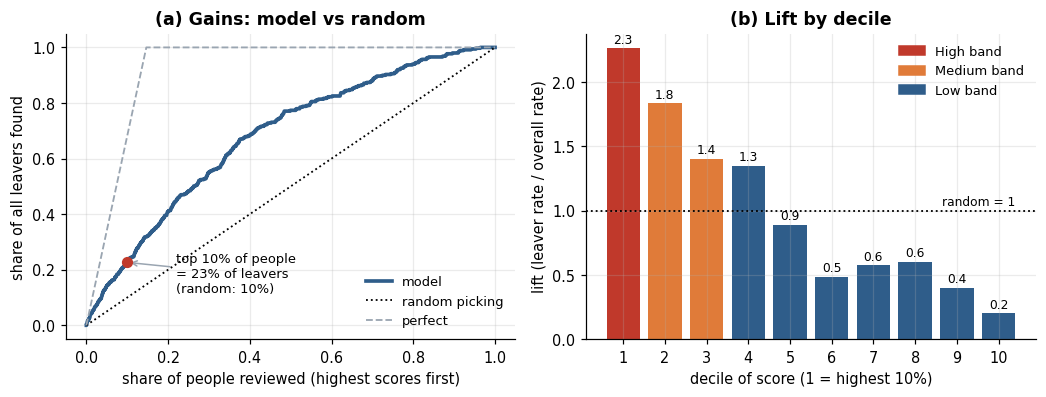

In [9]:
lt = lift_table(y, score_cal, n_bins=10)
display(lt.round(3))
top = top_k_mask(score_cal, 0.10)
found, expected = int(y[top].sum()), 0.10 * R["leavers"]
print(f"Top 10% ({top.sum()} people): {found} real leavers. Picking {top.sum()} people at random would find about {expected:.0f} -> {found / expected:.2f}x as many.")
print(f"Top 20%: {lt.cumulative_share_of_leavers.iloc[1]:.1%} of leavers | top 30%: {lt.cumulative_share_of_leavers.iloc[2]:.1%} | top 40%: {lt.cumulative_share_of_leavers.iloc[3]:.1%}")
R["lift_table"] = lt.to_dict("records"); R["top10"] = {"people": int(top.sum()), "found": found, "random_expected": expected, "lift": found / expected}

x, g = gains_curve(y, score_cal)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 3.7))
a1.plot(x, g, color=BLUE, lw=2.4, label="model")
a1.plot([0, 1], [0, 1], ":", color="k", lw=1.2, label="random picking")
a1.plot([0, y.mean(), 1], [0, 1, 1], "--", color=GREY, lw=1.2, label="perfect")
a1.scatter([0.10], [found / R["leavers"]], color=RED, zorder=5, s=40)
a1.annotate(f"top 10% of people\n= {found / R['leavers']:.0%} of leavers\n(random: 10%)", xy=(0.10, found / R["leavers"]), xytext=(0.22, 0.12), fontsize=8.5, arrowprops=dict(arrowstyle="->", color=GREY))
a1.set_xlabel("share of people reviewed (highest scores first)"); a1.set_ylabel("share of all leavers found"); a1.set_title("(a) Gains: model vs random"); a1.legend(frameon=False, fontsize=8.5, loc="lower right")
cols = [BAND_COLOURS["High"]] + [BAND_COLOURS["Medium"]] * 2 + [BAND_COLOURS["Low"]] * 7
a2.bar(lt.group, lt.lift, color=cols); a2.axhline(1, ls=":", color="k", lw=1.2); a2.text(10.4, 1.04, "random = 1", fontsize=8, ha="right")
for gx, v in zip(lt.group, lt.lift): a2.text(gx, v + .04, f"{v:.1f}", ha="center", fontsize=8)
a2.set_xticks(lt.group); a2.set_xlabel("decile of score (1 = highest 10%)"); a2.set_ylabel("lift (leaver rate / overall rate)"); a2.set_title("(b) Lift by decile")
from matplotlib.patches import Patch
a2.legend(handles=[Patch(color=RED, label="High band"), Patch(color=ORANGE, label="Medium band"), Patch(color=BLUE, label="Low band")], frameon=False, fontsize=8.5, loc="upper right")
plt.tight_layout(); plt.savefig(FIGURES / "fig8_lift.png"); plt.show()

**Reading it.** The top 10% contains about 2.3 times the leavers of a random 10%, and the lift falls steadily down the list, which is what a useful ranking looks like. Two honest limits: the curve is modest (it is far from the grey "perfect" line), and the lowest-lift deciles still contain leavers. (Small bumps, such as decile 8 vs 7, are noise at this sample size.)

Note that decile 4 sits in the **Low** band yet still has an above-average leaver rate (lift about 1.3): *Low* means "lower than the others", not "safe". About 45% of all leavers are in the Low band.

## 7. Are the results stable?
Three checks: the five folds separately, the two row sources separately, and bootstrap noise.

In [10]:
rows = []
for i, (tr, te) in enumerate(folds, 1):
    r = binary_report(y.iloc[te], score_cal[te])
    rows.append({"fold": i, "people": len(te), "leavers": int(y.iloc[te].sum()), "roc_auc": r["roc_auc"], "pr_auc": r["pr_auc"],
                 "precision_top10%": r["precision_at_top"], "recall_top10%": r["recall_at_top"], "lift_top10%": r["lift_at_top"]})
per_fold = pd.DataFrame(rows); display(per_fold.round(3))
summ = per_fold.drop(columns=["fold", "people", "leavers"]).agg(["mean", "std"]).round(3); display(summ)
R["per_fold"] = per_fold.to_dict("records"); R["per_fold_summary"] = summ.to_dict()

rows = []
for s_name in sorted(source.unique()):
    m = (source == s_name).values
    r = binary_report(y[m], score_cal[m]); inh = (bands[m] == "High").values
    lo_s, hi_s = bootstrap_ci(lambda a, s: binary_report(a, s)["roc_auc"], y[m], score_cal[m])
    rows.append({"rows": s_name, "people": int(m.sum()), "leavers": int(y[m].sum()), "roc_auc": round(r["roc_auc"], 3), "roc_auc_95%": f"{lo_s:.2f} to {hi_s:.2f}",
                 "in High band": int(inh.sum()), "leavers in High": int(y[m][inh].sum()),
                 "High-band leaver rate": round(y[m][inh].mean(), 3), "share of this source's leavers in High": round(y[m][inh].sum() / y[m].sum(), 3)})
per_source = pd.DataFrame(rows); display(per_source); R["per_source"] = per_source.to_dict("records")

,fold,people,leavers,roc_auc,pr_auc,precision_top10%,recall_top10%,lift_top10%
0,1,476,70,0.681,0.320,0.333,0.229,2.267
1,2,476,70,0.736,0.332,0.312,0.214,2.125
2,3,476,70,0.718,0.319,0.333,0.229,2.267
3,4,476,70,0.713,0.281,0.375,0.257,2.550
4,5,475,69,0.716,0.302,0.375,0.261,2.582


,roc_auc,pr_auc,precision_top10%,recall_top10%,lift_top10%
mean,0.713,0.311,0.346,0.238,2.358
std,0.020,0.020,0.028,0.020,0.199


,rows,people,leavers,roc_auc,roc_auc_95%,in High band,leavers in High,High-band leaver rate,share of this source's leavers in High
0,historical_extension,2000,299,0.714,0.68 to 0.75,218,73,0.335,0.244
1,master_employee_snapshot,379,50,0.691,0.61 to 0.77,20,6,0.300,0.120


**What the checks say.** Fold by fold the top-10% numbers stay in a similar range (see the table), so the result is not an accident of one split. The two row sources differ: on the 379 master-snapshot employees the ranking is weaker and the High band holds only a handful of people (and leavers), so that result is much less certain. Bands were cut across all rows together; the manager note says this plainly.

## 8. Metrics table for all baselines
Two models (the Dummy and the depth-4 tree) give many people the *same* score, so their top-10% cut-off falls inside a group of ties. Picking among ties by row order would be arbitrary (the first rows in the sheet are lower-attrition master-snapshot rows), so their top-10% figures are the **average over 200 random tie-breaks**. After calibration almost nobody reaches 50% (see below), so yes/no numbers at 0.5 are shown only for the as-trained scores.

In [11]:
def report_avg_ties(s, seeds=range(200)):
    reps = [binary_report(y, s, tie_seed=sd) for sd in seeds]
    return {k: float(np.mean([r[k] for r in reps])) for k in reps[0] if isinstance(reps[0][k], float)}
n_above_half = int((score_cal >= 0.5).sum())
rows = []
def add(name, s, note, avg_ties=False, yes_no=True):
    r = report_avg_ties(s) if avg_ties else binary_report(y, s)
    rows.append({"model": name, "ROC-AUC": r["roc_auc"], "PR-AUC": r["pr_auc"], "top-10% precision": r["precision_at_top"], "top-10% recall": r["recall_at_top"],
                 "top-10% lift": r["lift_at_top"], "precision @0.5": r["precision"] if yes_no else np.nan, "recall @0.5": r["recall"] if yes_no else np.nan,
                 "accuracy @0.5": r["accuracy"] if yes_no else np.nan, "Brier": r["brier"], "note": note})
add("Dummy (always stays)", out_of_fold_proba(model_pipeline(models["Dummy (always stays)"]), X, y, folds), "all scores tied; top 10% = random pick (average of 200)", avg_ties=True)
add("Logistic regression, balanced (Task 3)", score, "ranking score, NOT a probability")
add("Logistic regression, balanced + calibration", score_cal, f"used for bands and the note; only {n_above_half} people reach 50%, so 0.5 yes/no is not meaningful", yes_no=False)
add("Decision tree, depth 4, balanced", out_of_fold_proba(model_pipeline(models["Decision Tree (depth 4, balanced)"]), X, y, folds), "few distinct scores; top 10% = average of 200 random tie-breaks", avg_ties=True)
metrics = pd.DataFrame(rows); metrics.to_csv(TABLES / "day4_metrics_table.csv", index=False)
display(metrics.round(3)); R["metrics_table"] = metrics.to_dict("records")
dummy_lift = metrics.set_index("model").loc["Dummy (always stays)", "top-10% lift"]
assert 0.9 < dummy_lift < 1.1                      # a random pick has lift about 1

,model,ROC-AUC,PR-AUC,top-10% precision,top-10% recall,top-10% lift,precision @0.5,recall @0.5,accuracy @0.5,Brier,note
0,Dummy (always stays),0.500,0.147,0.146,0.100,0.997,0.000,0.000,0.853,0.147,all scores tied; top 10% = random pick (average of 200)
1,"Logistic regression, balanced (Task 3)",0.710,0.298,0.332,0.226,2.263,0.263,0.633,0.686,0.206,"ranking score, NOT a probability"
2,"Logistic regression, balanced + calibration",0.711,0.296,0.332,0.226,2.263,NaN,NaN,NaN,0.116,"used for bands and the note; only 15 people reach 50%, so 0.5 yes/no is not meaningful"
3,"Decision tree, depth 4, balanced",0.645,0.248,0.329,0.224,2.242,0.236,0.524,0.681,0.221,few distinct scores; top 10% = average of 200 random tie-breaks


## 9. The one-page manager note
Written from the numbers above. Each factual claim is checked by an assertion first, so the note cannot drift away from the results. It is saved as `reports/day4_manager_note.md` (the Word/PDF versions are built from this file).

In [12]:
H, M_, L = high, med, low
ci_p = R["high_band_ci"]["precision"]
src = per_source.set_index("rows")
mast = src.loc["master_employee_snapshot"]
# ---- claims
assert H.leaver_rate > M_.leaver_rate > L.leaver_rate                         # bands are ordered
assert 2.0 < H.lift < 2.6 and 0.20 < H.share_of_all_leavers < 0.26             # 'about 2.3 times', 'about a quarter'
assert 0.40 < L.share_of_all_leavers < 0.50                                    # 'about 45% of leavers are in Low'
assert ece_c < 0.04 and ece > 0.2 and rep["brier"] > rep["brier_baseline"] > rep_cal["brier"]   # calibration story
assert (int(H.people), int(M_.people), int(L.people)) == (238, 476, 1665)
assert ".0 /" not in f"{int(H.people)} / {int(M_.people)}"      # counts are whole numbers
assert mast["leavers in High"] <= 8                                            # 'only a handful'
assert abs(mean_pred["High"] - H.leaver_rate) < 0.05                           # 'the percentages are honest'

note = f'''# Attrition risk score: a one-page guide for managers

**What the score is.** For each employee the model gives a risk score from 0% to 100%: its estimate of the chance of leaving within the next 12 months, based on pay, tenure, promotions, engagement, attendance and similar HR data. We sort everyone by score and split the list into three bands: **High** (the 10% with the highest scores), **Medium** (the next 20%) and **Low** (the other 70%). In our test that was {int(H.people)} / {int(M_.people)} / {int(L.people)} of {len(y):,} people.

**How well it works.** We tested it only on people the model had not seen. Overall {100 * y.mean():.1f}% of people left. In the High band {100 * H.leaver_rate:.0f}% did ({int(H.leavers)} of {int(H.people)}), about {H.lift:.1f} times the average; in Medium {100 * M_.leaver_rate:.0f}%; in Low {100 * L.leaver_rate:.0f}%. The percentages are honest: the High band's average score was {100 * mean_pred["High"]:.0f}% and {100 * H.leaver_rate:.0f}% of that group really left.

**What it cannot do.** It misses a lot. The High band holds only about {100 * H.share_of_all_leavers:.0f}% of everyone who left, and about {100 * L.share_of_all_leavers:.0f}% of leavers were in the Low band. About {100 * (1 - H.leaver_rate):.0f} in 100 people in the High band stayed. The score does not say why someone might leave, and it cannot know what you know, such as a recent conversation or a personal situation.

**What it is not.** It is not a verdict on any person, and not a reason to change someone's pay, promotion, workload or job. It must never be the basis for dismissal, discipline or a performance rating. **A score supports a human decision; it never makes one.**

**How to use it.**

1. Treat the High band as a prompt for a supportive check-in about workload, development and pay, led by someone who knows the person.
2. Look at each case yourself. Most people on the list will not leave.
3. Keep individual scores confidential and do not label anyone a "flight risk".
4. Use the Medium and Low bands only for team-level planning.
5. Expect to re-check the model regularly.

**Known limits.** It is built on only {R["leavers"]} leavers, so the numbers are uncertain: the High-band leaver rate could plausibly be anywhere from {100 * ci_p[0]:.0f}% to {100 * ci_p[1]:.0f}%. Most of the training data is simulated history; for the {int(mast.people)} employees in the current snapshot the ranking is weaker and only {int(mast["leavers in High"])} High-band people left. Fairness across groups has not been tested yet, and two data questions are still open with the data team.

![How many leavers the list finds, and how the bands compare](figures/fig8_lift.png)
'''
(REPORTS / "day4_manager_note.md").write_text(note, encoding="utf-8")
R["note_words"] = len(note.split())
print("words:", R["note_words"]); display(Markdown(note.replace("](figures/", "](../reports/figures/")))

words: 414


# Attrition risk score: a one-page guide for managers

**What the score is.** For each employee the model gives a risk score from 0% to 100%: its estimate of the chance of leaving within the next 12 months, based on pay, tenure, promotions, engagement, attendance and similar HR data. We sort everyone by score and split the list into three bands: **High** (the 10% with the highest scores), **Medium** (the next 20%) and **Low** (the other 70%). In our test that was 238 / 476 / 1665 of 2,379 people.

**How well it works.** We tested it only on people the model had not seen. Overall 14.7% of people left. In the High band 33% did (79 of 238), about 2.3 times the average; in Medium 24%; in Low 9%. The percentages are honest: the High band's average score was 35% and 33% of that group really left.

**What it cannot do.** It misses a lot. The High band holds only about 23% of everyone who left, and about 45% of leavers were in the Low band. About 67 in 100 people in the High band stayed. The score does not say why someone might leave, and it cannot know what you know, such as a recent conversation or a personal situation.

**What it is not.** It is not a verdict on any person, and not a reason to change someone's pay, promotion, workload or job. It must never be the basis for dismissal, discipline or a performance rating. **A score supports a human decision; it never makes one.**

**How to use it.**

1. Treat the High band as a prompt for a supportive check-in about workload, development and pay, led by someone who knows the person.
2. Look at each case yourself. Most people on the list will not leave.
3. Keep individual scores confidential and do not label anyone a "flight risk".
4. Use the Medium and Low bands only for team-level planning.
5. Expect to re-check the model regularly.

**Known limits.** It is built on only 349 leavers, so the numbers are uncertain: the High-band leaver rate could plausibly be anywhere from 27% to 39%. Most of the training data is simulated history; for the 379 employees in the current snapshot the ranking is weaker and only 6 High-band people left. Fairness across groups has not been tested yet, and two data questions are still open with the data team.

![How many leavers the list finds, and how the bands compare](../reports/figures/fig8_lift.png)


In [13]:
# row-level scores for the team (no employee ids; written to the git-ignored data/processed folder)
out = pd.DataFrame({"row": y.index, "source": source.values, "actual_left": y.values, "score_as_trained": score.round(4),
                    "risk_score_calibrated": score_cal.round(4), "risk_band": bands.astype(str).values})
out.to_csv(DATA_PROCESSED / "day4_oof_scores.csv", index=False)
bs.to_csv(TABLES / "day4_risk_band_summary.csv", index=False); cal.to_csv(TABLES / "day4_calibration_as_trained.csv", index=False); cal_c.to_csv(TABLES / "day4_calibration_calibrated.csv", index=False)
lt.to_csv(TABLES / "day4_lift_table.csv", index=False); per_fold.to_csv(TABLES / "day4_per_fold.csv", index=False); per_source.to_csv(TABLES / "day4_per_source.csv", index=False)
R["random_state"] = RANDOM_STATE
(TABLES / "day4_findings.json").write_text(json.dumps(R, indent=2, default=str), encoding="utf-8")
print("saved: tables day4_*.csv, day4_findings.json, figures fig7/fig8, reports/day4_manager_note.md, data/processed/day4_oof_scores.csv (git-ignored)")

saved: tables day4_*.csv, day4_findings.json, figures fig7/fig8, reports/day4_manager_note.md, data/processed/day4_oof_scores.csv (git-ignored)
